# 06 — Clustering: types of communes

Do communes fall into distinct types (e.g. high-income expat hubs, industrial towns, resorts, rural villages), and does the foreign share relate differently to tax and social assistance in each type?

Communes are grouped on their structure (size, density, housing, age, jobs, foreign residents and their composition). Tax and social assistance are NOT used to build the groups; they are compared across groups afterwards.

Input: `data/processed/communes_2022.csv`. Output: `Results/clustering/`.

## 1. Variables that describe a commune
13 structural variables. Hidden values (small communes) are replaced by the canton median; very skewed variables are log-transformed; all are standardised.

In [1]:
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
sys.path.append("../code")
import helpers

df, tax_sample, sa_sample = helpers.load_model_samples()
OUT = helpers.results_dir("clustering")

# Job structure: share of the commune's jobs in industry and in agriculture
df["industry_share_jobs"] = 100 * df["jobs_secondary"] / df["jobs_total"]
df["agriculture_share_jobs"] = 100 * df["jobs_primary"] / df["jobs_total"]

# What describes a commune (its structure). NOT tax or social assistance: they are
# used afterwards, to see whether the types differ fiscally.
cluster_vars = {
    "log_population": "Population (log)",
    "log_density": "Density (log)",
    "share_under20": "Under 20 (%)",
    "share_65plus": "Aged 65+ (%)",
    "jobs_per_capita": "Jobs per resident",
    "industry_share_jobs": "Jobs in industry (%)",
    "agriculture_share_jobs": "Jobs in agriculture (%)",
    "share_single_family": "Residents of single-family houses (%)",
    "foreign_share": "Foreign residents (%)",
    "neighbour_share_foreign": "German + French (% of foreigners)",
    "share_L": "L permits, short stays (% of pop.)",
    "share_asylum": "Asylum-related permits (% of pop.)",
    "share_intl": "International officials (% of pop.)",
}
X = df[list(cluster_vars)].copy()

# Hidden values (small numbers kept secret) -> median of the same canton
missing = X.isna().sum()
for col in X.columns[X.isna().any()]:
    X[col] = X[col].fillna(X.groupby(df["canton"])[col].transform("median"))
    X[col] = X[col].fillna(X[col].median())       # a canton where all are hidden
assert X.notna().all().all()

# Very skewed variables (a few communes with huge values) -> log(1 + x), so that
# a handful of extreme communes do not decide the clusters on their own
skew_before = X.skew()
for col in ["jobs_per_capita", "share_L", "share_asylum", "share_intl"]:
    X[col] = np.log1p(X[col])

# Standardise: every variable gets mean 0 and SD 1, so each counts equally in distances
X_std = pd.DataFrame(StandardScaler().fit_transform(X), columns=X.columns, index=X.index)

table_vars = pd.DataFrame({
    "Variable": cluster_vars.values(),
    "Hidden values imputed": missing.values,
    "Skewness (raw)": skew_before.round(2).values,
    "Skewness (used)": X.skew().round(2).values,
}, index=list(cluster_vars))
table_vars.to_csv(OUT / "table_clustering_variables.csv")
print(X_std.shape)
table_vars

(2115, 13)


,Variable,Hidden values imputed,Skewness (raw),Skewness (used)
log_population,Population (log),0,0.07,0.07
log_density,Density (log),0,-0.38,-0.38
share_under20,Under 20 (%),2,-0.59,-0.59
share_65plus,Aged 65+ (%),0,0.94,0.94
jobs_per_capita,Jobs per resident,0,4.11,1.93
industry_share_jobs,Jobs in industry (%),65,0.83,0.83
agriculture_share_jobs,Jobs in agriculture (%),48,1.70,1.70
share_single_family,Residents of single-family houses (%),0,0.02,0.02
foreign_share,Foreign residents (%),6,0.83,0.83
neighbour_share_foreign,German + French (% of foreigners),566,0.92,0.92


## 2. PCA: a few axes that summarise the 13 variables
Components are kept if their eigenvalue is above the 95th percentile of eigenvalues from shuffled data (each column permuted separately, 100 times). Loadings show what each component measures.

,Eigenvalue,Noise (95th percentile),Variance explained (%),Cumulative (%)
PC1,3.82,1.16,29.38,29.38
PC2,2.10,1.12,16.18,45.55
PC3,1.25,1.09,9.64,55.19
PC4,1.10,1.07,8.42,63.62
PC5,0.96,1.05,7.41,71.03
PC6,0.77,1.03,5.95,76.98
PC7,0.72,1.01,5.52,82.50
PC8,0.63,0.99,4.85,87.35
PC9,0.50,0.98,3.85,91.21
PC10,0.42,0.96,3.25,94.46


Components above noise: 4


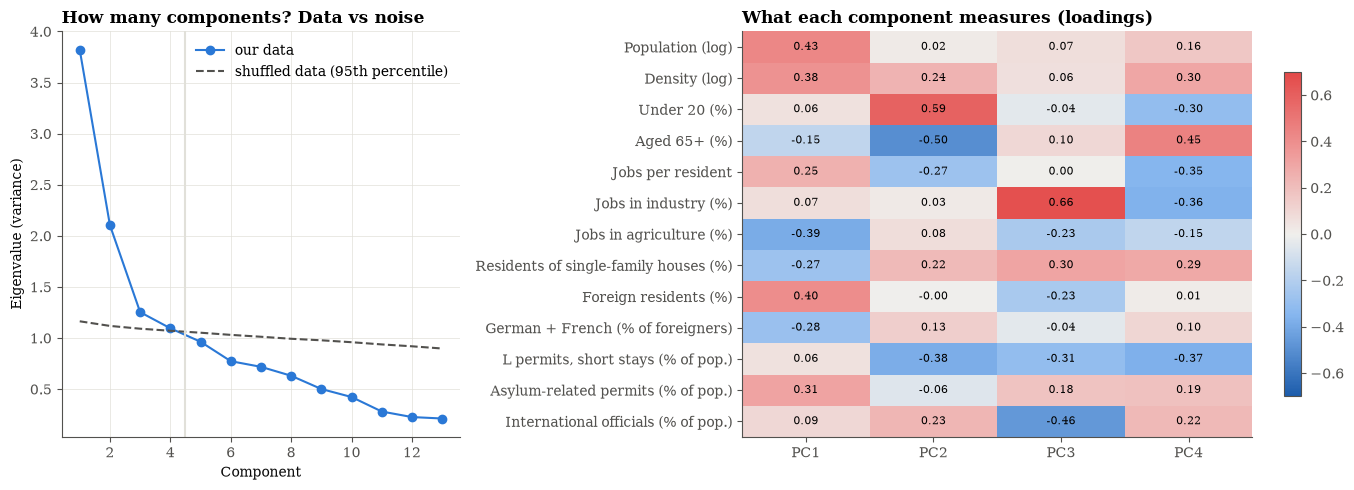

In [2]:
from sklearn.decomposition import PCA

pca = PCA(random_state=helpers.SEED).fit(X_std)
eigenvalues = pca.explained_variance_

# How many components carry real structure? Compare with data where each column is
# shuffled on its own: same variables, but every link between them is destroyed.
rng = np.random.default_rng(helpers.SEED)
noise = []
for _ in range(100):
    shuffled = np.column_stack([rng.permutation(X_std[col].to_numpy()) for col in X_std])
    noise.append(PCA().fit(shuffled).explained_variance_)
noise_95 = np.percentile(noise, 95, axis=0)
n_keep = int(np.argmax(eigenvalues < noise_95))      # first component that is not above noise

table_pca = pd.DataFrame({
    "Eigenvalue": eigenvalues,
    "Noise (95th percentile)": noise_95,
    "Variance explained (%)": 100 * pca.explained_variance_ratio_,
    "Cumulative (%)": 100 * pca.explained_variance_ratio_.cumsum(),
}, index=[f"PC{k + 1}" for k in range(len(eigenvalues))]).round(2)
table_pca.to_csv(OUT / "table_pca_variance.csv")
display(table_pca)
print(f"Components above noise: {n_keep}")

# What each kept component measures: its weight on each variable (loadings)
loadings = pd.DataFrame(pca.components_[:n_keep], columns=list(cluster_vars.values()),
                        index=[f"PC{k + 1}" for k in range(n_keep)])
loadings.round(3).to_csv(OUT / "table_pca_loadings.csv")

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5), gridspec_kw={"width_ratios": [1, 1.6]})

# (a) Scree plot: eigenvalues against what pure noise would give
k = np.arange(1, len(eigenvalues) + 1)
ax1.plot(k, eigenvalues, marker="o", color=helpers.COLORS["urban_rural"]["urban"], label="our data")
ax1.plot(k, noise_95, linestyle="--", color=helpers.INK["secondary"], label="shuffled data (95th percentile)")
ax1.axvline(n_keep + 0.5, color=helpers.INK["grid"])
ax1.set_xlabel("Component")
ax1.set_ylabel("Eigenvalue (variance)")
ax1.set_title("How many components? Data vs noise")
ax1.legend(frameon=False)
ax1.grid(color=helpers.INK["grid"], linewidth=0.5)

# (b) Loadings: red = the component rises with the variable, blue = falls
image = ax2.imshow(loadings.T, cmap=helpers.DIVERGING, vmin=-0.7, vmax=0.7, aspect="auto")
ax2.set_xticks(range(n_keep), loadings.index)
ax2.set_yticks(range(len(cluster_vars)), loadings.columns)
for i in range(len(cluster_vars)):
    for j in range(n_keep):
        ax2.text(j, i, f"{loadings.iloc[j, i]:.2f}", ha="center", va="center", fontsize=8)
ax2.set_title("What each component measures (loadings)")
fig.colorbar(image, ax=ax2, shrink=0.8)

fig.tight_layout()
helpers.save_figure(fig, OUT / "fig_pca.png")
plt.show()

# Coordinates of every commune on the kept components: the input of the clustering
scores = pd.DataFrame(pca.transform(X_std)[:, :n_keep], index=X_std.index,
                      columns=[f"PC{k + 1}" for k in range(n_keep)])

## 3. How many groups?
k-means, Ward's hierarchical clustering and a Gaussian mixture for k = 2 to 10, on the 4 principal components. Criteria: within-group spread (elbow), silhouette, BIC, and stability of k-means over 20 bootstrap samples (adjusted Rand index).

,k-means: within-group spread,k-means: silhouette,k-means: Calinski-Harabasz,Ward: silhouette,Gaussian mixture: BIC,k-means: stability (ARI),k-means: smallest group
k,,,,,,,
2,12183.906,0.287,920.385,0.251,28137.302,0.945,909
3,10039.112,0.276,783.852,0.192,27626.477,0.907,316
4,8728.057,0.218,706.478,0.190,27289.986,0.872,277
5,7804.324,0.218,654.731,0.199,27334.837,0.783,147
6,6983.964,0.225,634.577,0.164,27391.853,0.819,49
7,6453.347,0.214,600.915,0.169,27450.815,0.690,48
8,5979.565,0.209,579.503,0.169,27526.755,0.657,45
9,5579.818,0.202,561.968,0.159,27594.632,0.714,39
10,5286.969,0.197,539.891,0.156,27669.541,0.640,37


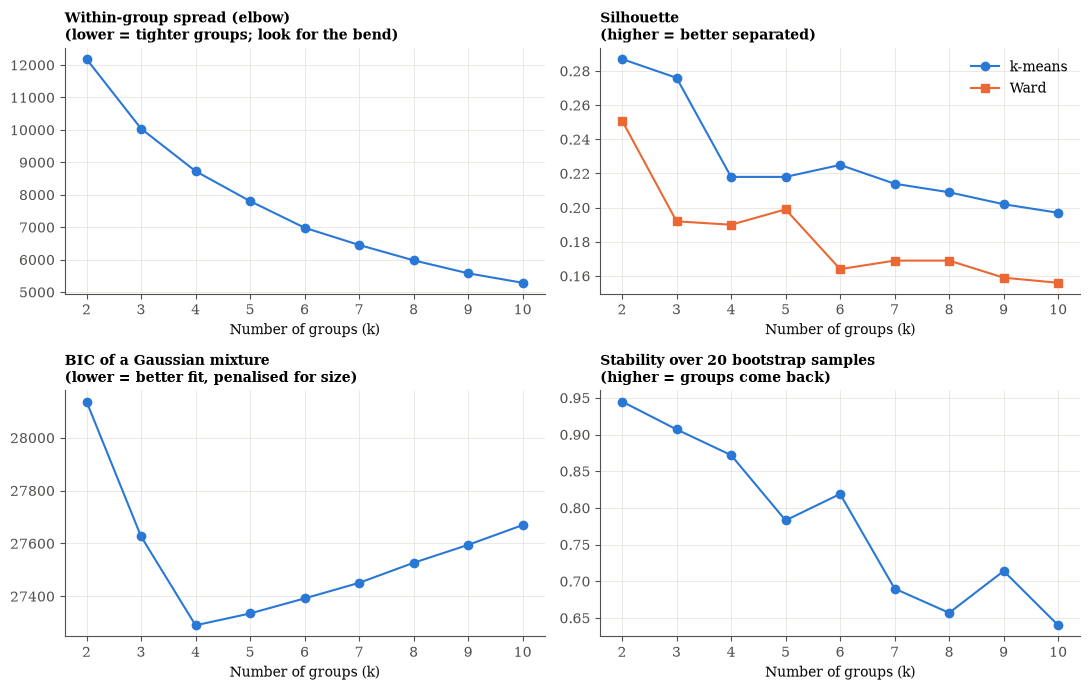

In [3]:
from sklearn.cluster import AgglomerativeClustering, KMeans
from sklearn.metrics import adjusted_rand_score, calinski_harabasz_score, silhouette_score
from sklearn.mixture import GaussianMixture

ks = range(2, 11)
rows = []
for k in ks:
    kmeans = KMeans(n_clusters=k, n_init=20, random_state=helpers.SEED).fit(scores)
    ward = AgglomerativeClustering(n_clusters=k, linkage="ward").fit(scores)
    gmm = GaussianMixture(n_components=k, n_init=5, random_state=helpers.SEED).fit(scores)

    # Stability: k-means on 20 bootstrap samples; how similar are its groups to the
    # groups on the full data? (adjusted Rand index: 1 = identical, 0 = random)
    rng = np.random.default_rng(helpers.SEED)
    agreement = []
    for _ in range(20):
        sample = rng.choice(len(scores), len(scores), replace=True)
        boot = KMeans(n_clusters=k, n_init=10, random_state=helpers.SEED).fit(scores.iloc[sample])
        agreement.append(adjusted_rand_score(kmeans.labels_, boot.predict(scores)))

    rows.append({
        "k": k,
        "k-means: within-group spread": kmeans.inertia_,
        "k-means: silhouette": silhouette_score(scores, kmeans.labels_),
        "k-means: Calinski-Harabasz": calinski_harabasz_score(scores, kmeans.labels_),
        "Ward: silhouette": silhouette_score(scores, ward.labels_),
        "Gaussian mixture: BIC": gmm.bic(scores),
        "k-means: stability (ARI)": np.mean(agreement),
        "k-means: smallest group": np.bincount(kmeans.labels_).min(),
    })

table_k = pd.DataFrame(rows).set_index("k").round(3)
table_k.to_csv(OUT / "table_number_of_clusters.csv")
display(table_k)

fig, axes = plt.subplots(2, 2, figsize=(11, 7))
panels = [
    ("k-means: within-group spread", "Within-group spread (elbow)", "lower = tighter groups; look for the bend"),
    ("k-means: silhouette", "Silhouette", "higher = better separated"),
    ("Gaussian mixture: BIC", "BIC of a Gaussian mixture", "lower = better fit, penalised for size"),
    ("k-means: stability (ARI)", "Stability over 20 bootstrap samples", "higher = groups come back"),
]
for ax, (column, title, note) in zip(axes.flat, panels):
    ax.plot(list(ks), table_k[column], marker="o", color=helpers.COLORS["urban_rural"]["urban"], label="k-means"
            if column == "k-means: silhouette" else None)
    if column == "k-means: silhouette":
        ax.plot(list(ks), table_k["Ward: silhouette"], marker="s", color=helpers.COLORS["urban_rural"]["intermediate"],
                label="Ward")
        ax.legend(frameon=False)
    ax.set_title(f"{title}\n({note})", fontsize=10)
    ax.set_xlabel("Number of groups (k)")
    ax.grid(color=helpers.INK["grid"], linewidth=0.5)
fig.tight_layout()
helpers.save_figure(fig, OUT / "fig_number_of_clusters.png")
plt.show()

## 4. Four types of communes
k-means with 4 groups on the principal components. Types are numbered from the least to the most urban (mean score on the first component). Profile: medians of the original variables.

Agreement with Ward: 0.43 | with Gaussian mixture: 0.38


,Type 1,Type 2,Type 3,Type 4
Population (median),742.5,697.0,2417.0,6884.9
"Density (residents per km², median)",105.2,24.7,262.9,891.3
Under 20 (%),21.9,16.1,20.7,20.2
Aged 65+ (%),19.0,26.5,19.6,19.1
Jobs per resident,0.2,0.4,0.4,0.5
Jobs in industry (%),19.5,16.7,31.8,22.3
Jobs in agriculture (%),27.1,15.5,7.6,1.3
Residents of single-family houses (%),46.2,34.5,42.8,25.4
Foreign residents (%),10.8,12.0,16.1,28.9
German + French (% of foreigners),40.4,34.4,26.6,16.8


,Largest communes
type,
1,"Troistorrents, Hautemorges, Reichenbach im Kan..."
2,"Ilanz/Glion, Sigriswil, Scuol, Klosters, Lens"
3,"Val-de-Ruz, Einsiedeln, Blonay - Saint-Légier,..."
4,"Zürich, Genève, Basel, Lausanne, Bern"


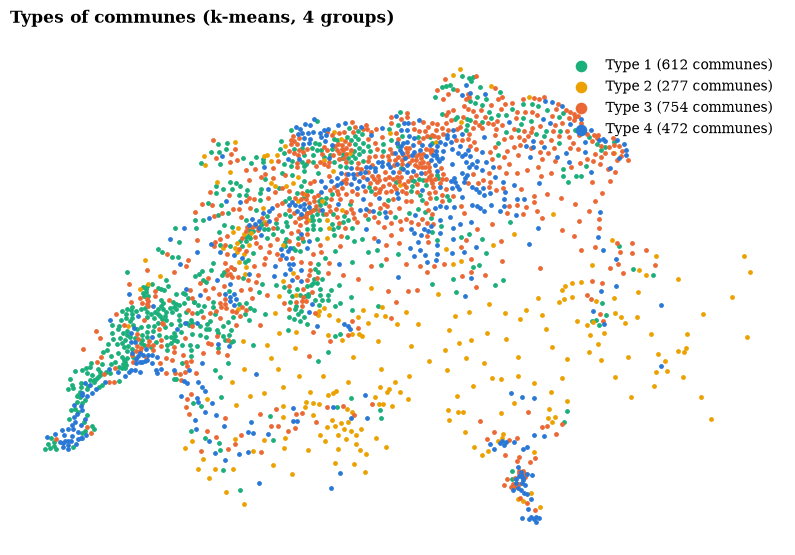

In [4]:
K = 4

# Final grouping: k-means with 4 groups on the 4 principal components
final = KMeans(n_clusters=K, n_init=50, random_state=helpers.SEED).fit(scores)

# Number the types from the least to the most urban (mean score on PC1), so that the
# numbering is the same every time the notebook runs
order = scores.groupby(final.labels_)["PC1"].mean().sort_values().index
renumber = {old: new for new, old in enumerate(order, start=1)}
df["type"] = pd.Series(final.labels_, index=scores.index).map(renumber)

# Do the other two methods find similar groups? (adjusted Rand index, 1 = identical)
ward4 = AgglomerativeClustering(n_clusters=K, linkage="ward").fit(scores).labels_
gmm4 = GaussianMixture(n_components=K, n_init=5, random_state=helpers.SEED).fit(scores).predict(scores)
print(f"Agreement with Ward: {adjusted_rand_score(df['type'], ward4):.2f} | "
      f"with Gaussian mixture: {adjusted_rand_score(df['type'], gmm4):.2f}")

# Profile of each type: medians of the original (not standardised) variables
df["urban"] = (df["urban_rural"] == "urban") * 100
df["french_speaking"] = (df["language"] == "French") * 100
names = {**cluster_vars, "urban": "Urban communes (%)", "french_speaking": "French-speaking (%)"}
profile = df.groupby("type")[list(cluster_vars)].median()
profile[["urban", "french_speaking"]] = df.groupby("type")[["urban", "french_speaking"]].mean()
profile["Communes"] = df["type"].value_counts().sort_index()
profile["Share of Swiss population (%)"] = 100 * df.groupby("type")["population"].sum() / df["population"].sum()
profile = profile.rename(columns=names)
profile["Population (log)"] = np.exp(profile["Population (log)"])        # back to residents
profile["Density (log)"] = np.exp(profile["Density (log)"])              # back to residents per km²
profile = profile.rename(columns={"Population (log)": "Population (median)",
                                  "Density (log)": "Density (residents per km², median)"})
profile = profile.T.round(1)
profile.columns = [f"Type {t}" for t in profile.columns]
profile.to_csv(OUT / "table_type_profiles.csv")
display(profile)

# Examples: the five largest communes of each type
examples = (df.sort_values("population", ascending=False).groupby("type")["name"]
              .apply(lambda s: ", ".join(s.head(5))))
display(examples.to_frame("Largest communes"))

# Map: one dot per commune, coloured by type
type_colors = {1: helpers.COLORS["urban_rural"]["rural"], 2: helpers.COLORS["language"]["Romansh"],
               3: helpers.COLORS["urban_rural"]["intermediate"], 4: helpers.COLORS["urban_rural"]["urban"]}
fig, ax = plt.subplots(figsize=(10, 6.5))
for t, color in type_colors.items():
    part = df[df["type"] == t]
    ax.scatter(part["x_lv95"], part["y_lv95"], s=6, color=color, label=f"Type {t} ({len(part)} communes)")
ax.set_aspect("equal")
ax.set_axis_off()
ax.legend(frameon=False, markerscale=3, loc="upper right")
ax.set_title("Types of communes (k-means, 4 groups)")
helpers.save_figure(fig, OUT / "fig_types_map.png")
plt.show()

## 5. Fiscal profile of each type, and the foreign-share slope within each type
Tax and social assistance were not used to build the types. Within-type slopes use the M4 controls and canton fixed effects of notebook 04, with standard errors clustered by canton.

,Communes,"Tax per resident (CHF, median)","SA rate (%, median)",SA reported (communes),"Foreign residents (%, median)"
type_name,,,,,
Agricultural villages,612,772.7,1.4,341,10.8
Alpine and resort communes,277,605.2,1.0,121,12.0
Small industrial towns,754,789.1,1.4,696,16.1
Cities and agglomerations,472,888.9,2.5,467,28.9


,Tax (log),SA rate (pp)
Agricultural villages,0.0371*** (0.0067),0.0093 (0.0338)
Alpine and resort communes,0.0351*** (0.0089),0.0044 (0.0188)
Small industrial towns,-0.0020 (0.0051),0.0444*** (0.0130)
Cities and agglomerations,-0.0118** (0.0049),0.0437*** (0.0146)
p-value: same slope in all types,0.0,0.141
N,2108,1625


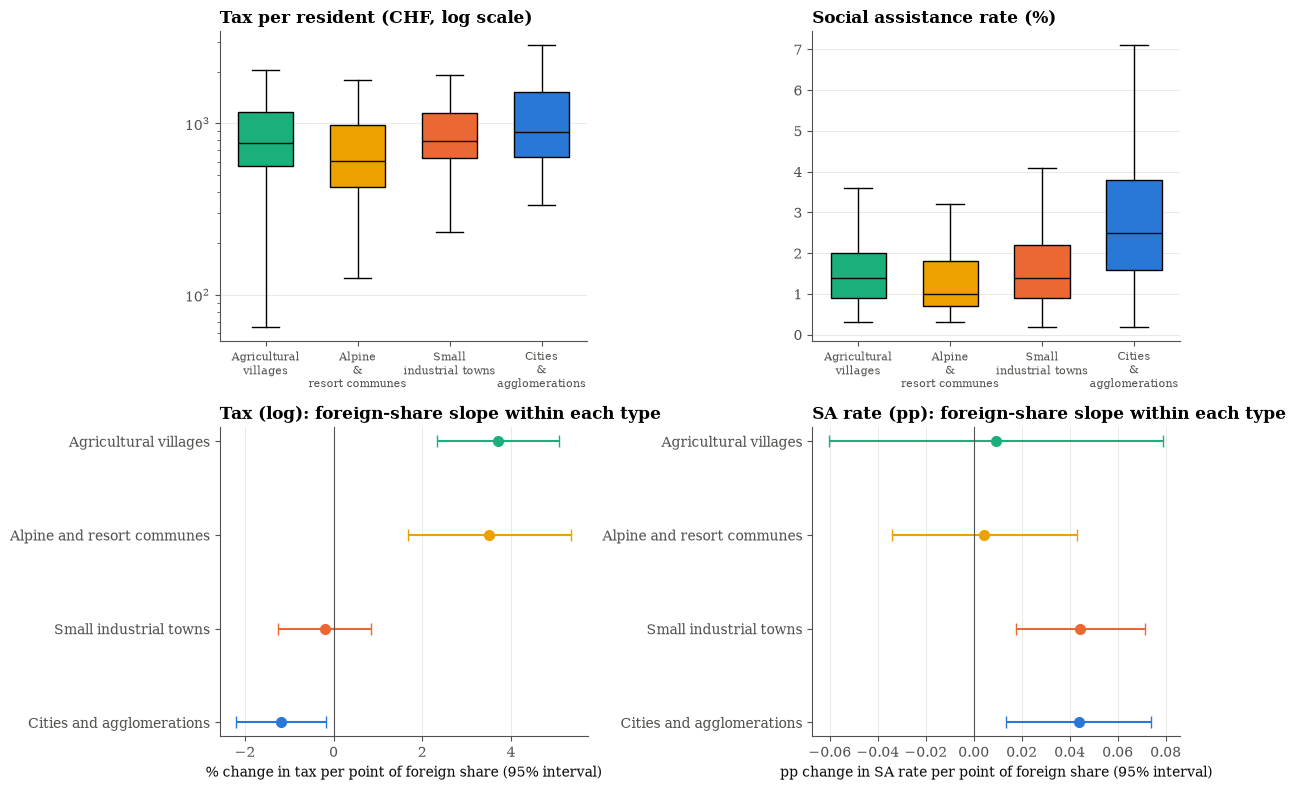

In [5]:
import statsmodels.formula.api as smf

type_names = {1: "Agricultural villages", 2: "Alpine and resort communes",
              3: "Small industrial towns", 4: "Cities and agglomerations"}
df["type_name"] = df["type"].map(type_names)
type_colors_named = {type_names[t]: c for t, c in type_colors.items()}

# (a) Do tax and social assistance differ between the types?
outcomes_by_type = pd.DataFrame({
    "Communes": df["type_name"].value_counts(),
    "Tax per resident (CHF, median)": df.groupby("type_name")["tax_per_capita"].median(),
    "SA rate (%, median)": df.groupby("type_name")["sa_rate"].median(),
    "SA reported (communes)": df.groupby("type_name")["sa_rate"].count(),
    "Foreign residents (%, median)": df.groupby("type_name")["foreign_share"].median(),
}).loc[list(type_names.values())].round(1)
outcomes_by_type.to_csv(OUT / "table_outcomes_by_type.csv")
display(outcomes_by_type)

# (b) Within each type: how does foreign share relate to tax and SA? Same controls and
# canton fixed effects as model M4 (notebook 04), one foreign-share slope per type.
for sample in (tax_sample, sa_sample):
    sample["type"] = df.loc[sample.index, "type"]
controls = helpers.M4_OTHER_CONTROLS + " + C(type)"
slope = {t: f"C(type)[{t}]:foreign_share" for t in type_names}

rows, fits = {}, {}
for label, sample, outcome in [("Tax (log)", tax_sample, "log_tax"), ("SA rate (pp)", sa_sample, "sa_rate")]:
    m = helpers.fit_clustered(f"{outcome} ~ {controls} + C(type):foreign_share", sample)
    fits[label] = m
    column = {type_names[t]: f"{m.params[slope[t]]:.4f}{helpers.stars(m.pvalues[slope[t]])} "
                             f"({m.bse[slope[t]]:.4f})" for t in type_names}
    equal = ", ".join(f"{slope[a]} = {slope[b]}" for a, b in zip(list(type_names)[:-1], list(type_names)[1:]))
    column["p-value: same slope in all types"] = round(float(m.f_test(equal).pvalue), 3)
    column["N"] = int(m.nobs)
    rows[label] = column

table_slopes = pd.DataFrame(rows)
table_slopes.to_csv(OUT / "table_foreign_share_slopes_by_type.csv")
display(table_slopes)

# Figure: top row = outcomes by type; bottom row = foreign-share slope within each type
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
order = list(type_names.values())
short = [n.replace(" and ", " &\n").replace(" ", "\n", 1) for n in order]
for ax, column, title in [(axes[0, 0], "tax_per_capita", "Tax per resident (CHF, log scale)"),
                          (axes[0, 1], "sa_rate", "Social assistance rate (%)")]:
    data = [df.loc[df["type_name"] == name, column].dropna() for name in order]
    box = ax.boxplot(data, patch_artist=True, showfliers=False, widths=0.6,
                     medianprops={"color": helpers.INK["primary"]})
    for patch, name in zip(box["boxes"], order):
        patch.set_facecolor(type_colors_named[name])
    ax.set_xticks(range(1, 5), short, fontsize=8)
    if column == "tax_per_capita":
        ax.set_yscale("log")
    ax.set_title(title)
    ax.grid(axis="y", color=helpers.INK["grid"], linewidth=0.5)

for ax, (label, m) in zip(axes[1], fits.items()):
    scale = 100 if label.startswith("Tax") else 1
    ci = m.conf_int()
    for i, t in enumerate(type_names):
        coef = m.params[slope[t]] * scale
        ax.errorbar(coef, i, xerr=[[coef - ci.loc[slope[t], 0] * scale], [ci.loc[slope[t], 1] * scale - coef]],
                    fmt="o", capsize=4, markersize=7, color=type_colors[t])
    ax.axvline(0, color=helpers.INK["secondary"], linewidth=0.8)
    ax.set_yticks(range(4), order)
    ax.invert_yaxis()
    unit = "% change in tax" if scale == 100 else "pp change in SA rate"
    ax.set_xlabel(f"{unit} per point of foreign share (95% interval)")
    ax.set_title(f"{label}: foreign-share slope within each type")
    ax.grid(axis="x", color=helpers.INK["grid"], linewidth=0.5)

fig.tight_layout()
helpers.save_figure(fig, OUT / "fig_types_outcomes_and_slopes.png")
plt.show()

## 6. Robustness: 3 to 6 types, and types without the nationality variable

In [6]:
def make_types(components, k):
    """k-means with k groups, numbered from the least to the most urban (mean PC1)."""
    km = KMeans(n_clusters=k, n_init=50, random_state=helpers.SEED).fit(components)
    order = components.groupby(km.labels_)["PC1"].mean().sort_values().index
    return pd.Series(km.labels_, index=components.index).map({old: new for new, old in enumerate(order, 1)})


def slopes_by_type(types):
    """Foreign-share slope within each type (M4 controls + type), for tax and SA."""
    result = {}
    for label, sample, outcome in [("Tax", tax_sample, "log_tax"), ("SA", sa_sample, "sa_rate")]:
        data = sample.assign(t=types.loc[sample.index])
        controls_t = controls.replace("C(type)", "C(t)")
        m = helpers.fit_clustered(f"{outcome} ~ {controls_t} + C(t):foreign_share", data)
        result[label] = {t: f"{m.params[f'C(t)[{t}]:foreign_share']:.4f}"
                            f"{helpers.stars(m.pvalues[f'C(t)[{t}]:foreign_share'])}"
                         for t in sorted(types.unique())}
    return result


# (1) The same analysis with 3, 4, 5 and 6 types
rows = []
for k in [3, 4, 5, 6]:
    types = make_types(scores, k)
    slopes = slopes_by_type(types)
    for t in sorted(types.unique()):
        members = df[types == t]
        rows.append({
            "k": k, "type (1 = least urban)": t, "communes": len(members),
            "urban (%)": round(100 * (members["urban_rural"] == "urban").mean()),
            "foreign share (median)": members["foreign_share"].median(),
            "intl officials (% pop., mean)": round(members["share_intl"].mean(), 2),
            "largest communes": ", ".join(members.nlargest(3, "population")["name"]),
            "tax slope": slopes["Tax"][t], "SA slope": slopes["SA"][t],
        })
table_k_robust = pd.DataFrame(rows).set_index(["k", "type (1 = least urban)"])
table_k_robust.to_csv(OUT / "table_types_robustness_k.csv")
display(table_k_robust)

# (2) Do the 4 types change without the German + French variable (imputed in 566 communes)?
X_without = X_std.drop(columns="neighbour_share_foreign")
scores_without = pd.DataFrame(PCA(n_components=n_keep, random_state=helpers.SEED).fit_transform(X_without),
                              index=X_without.index, columns=[f"PC{j + 1}" for j in range(n_keep)])
types_without = make_types(scores_without, K)
print(f"Agreement of the 4 types with and without the nationality variable "
      f"(adjusted Rand index): {adjusted_rand_score(df['type'], types_without):.2f}")
print("Same type for", round(100 * (pd.crosstab(df["type"], types_without).max(axis=1).sum() / len(df))), "% of communes")

communes  urban (%)  foreign share (median)  \
k type (1 = least urban)                                                
3 1                            316          2                   11.85   
  2                           1017          7                   12.20   
  3                            782         55                   25.10   
4 1                            612          4                   10.80   
  2                            277          2                   12.00   
  3                            754         18                   16.10   
  4                            472         73                   28.90   
5 1                            404          3                    8.90   
  2                            451          6                   13.90   
  3                            147          5                   16.30   
  4                            673         20                   16.60   
  5                            440         75                   29.15   
6 1                            365          4                    9.00   
  2                            460          3                   12.50   
  3                            140          5                   17.35   
  4                            673         19                   16.70   
  5                             49         65                   34.50   
  6                            428         73                   28.35   

                          intl officials (% pop., mean)  \
k type (1 = least urban)                                  
3 1                                                0.01   
  2                                                0.11   
  3                                                0.23   
4 1                                                0.18   
  2                                                0.01   
  3                                                0.01   
  4                                                0.37   
5 1                                                0.01   
  2                                                0.34   
  3                                                0.00   
  4                                                0.01   
  5                                                0.30   
6 1                                                0.01   
  2                                                0.06   
  3                                                0.00   
  4                                                0.01   
  5                                                4.71   
  6                                                0.06   

                                                           largest communes  \
k type (1 = least urban)                                                      
3 1                                         Glarus Süd, Nendaz, Ilanz/Glion   
  2                                           Fully, Savièse, Schwarzenburg   
  3                                                   Zürich, Genève, Basel   
4 1                       Troistorrents, Hautemorges, Reichenbach im Kan...   
  2                                           Ilanz/Glion, Sigriswil, Scuol   
  3                           Val-de-Ruz, Einsiedeln, Blonay - Saint-Légier   
  4                                                   Zürich, Genève, Basel   
5 1                                                Savièse, Vechigen, Ayent   
  2                              Gurmels, Hautemorges, Belmont-sur-Lausanne   
  3                                     Davos, Val de Bagnes, Crans-Montana   
  4                                     Val-de-Ruz, Einsiedeln, Steffisburg   
  5                                                   Zürich, Genève, Basel   
6 1                                            Savièse, Vechigen, Sigriswil   
  2                                          Gurmels, Hautemorges, Attalens   
  3                                     Davos, Val de Bagnes, Crans-Montana   
  4                           Val-de-Ruz,

Agreement of the 4 types with and without the nationality variable (adjusted Rand index): 0.82
Same type for 94 % of communes


## 7. LaTeX versions of the main tables

In [7]:
paper_tables = {
    "table_clustering_variables": table_vars,
    "table_pca_variance": table_pca,
    "table_pca_loadings": loadings,
    "table_number_of_clusters": table_k,
    "table_type_profiles": profile,
    "table_outcomes_by_type": outcomes_by_type,
    "table_foreign_share_slopes_by_type": table_slopes,
    "table_types_robustness_k": table_k_robust,
}
for name, table in paper_tables.items():
    latex = table.to_latex(escape=True, na_rep="", float_format="%.3f")
    _ = (OUT / f"{name}.tex").write_text(latex, encoding="utf-8")
print("Saved:", len(paper_tables), "tables")

Saved: 8 tables


## 8. Summary

| Step | Result |
|---|---|
| Variables | 13 structural variables (size, density, housing, age, jobs by sector, foreign residents and their composition); tax and social assistance not used |
| PCA | 4 components above noise (64% of the variance): urban vs rural (carries the foreign share), young families vs ageing resorts, industrial vs international/tourist, residential retirement (weak) |
| Number of types | 4: lowest BIC, stable over bootstrap samples (ARI 0.87), no tiny group; silhouette low (≈ 0.2) at every k, so the types are regions of a continuum rather than separate groups; moderate agreement with Ward (0.43) and a Gaussian mixture (0.38) |
| The 4 types | agricultural villages (612 communes, 6% of the population), Alpine and resort communes (277, 3%), small industrial towns (754, 25%), cities and agglomerations (472, 66%); the map matches known geography although location was not used |
| Fiscal profile | cities have both the highest tax per resident (median CHF 889) and the highest social-assistance rate (2.5%); resorts the lowest of both |
| Foreign share within types | tax: +3.7% per point in villages and +3.5% in resorts, ≈ 0 in industrial towns, −1.2% in cities (equal slopes rejected, p < 0.001); social assistance: +0.044 pp in towns and cities, imprecise in villages and resorts |
| Robustness | the same pattern with 3, 5 and 6 types; with 6, an "international Geneva" type appears (49 communes; strongest negative tax and positive social-assistance slopes, but mostly one canton, so its standard errors are unreliable); 94% of communes keep their type without the imputed nationality variable |

Data-driven commune types reproduce, more sharply, the urban/rural contrast of notebooks 04 and 05: where foreign residents are few (villages, resorts), more of them go with higher tax per resident; in towns and cities, more of them go with more social assistance and equal or lower tax. The raw association of the foreign share with both higher tax and higher social assistance (notebook 03) therefore comes from different kinds of places. Rural and resort slopes rest on many small communes, and social-assistance slopes there are imprecise because many small communes hide their rates. All results are associations between communes.